# Fan-Shaped Focusing Grating Coupler in 3D -- Design Point and GDS Export

A compact **fan-shaped focusing grating coupler** that couples a 0.5 µm single-mode Si
wire to a **2.5 µm-spot lensed fiber**, characterized with a true 3D FDTD simulation.
It is the 3D counterpart of `notebooks/09_grating_coupler.ipynb`, which models a
uniform grating on a 2D x-z cross-section.

**Headline result.** η = **71 % (−1.49 dB) at 1.35 µm**, or **68.7 % (−1.63 dB)**
including the 3.3 % Fresnel loss at the chip surface. The device uses a 17.5° fan, 6
elliptical partial-etch lines and a metal mirror under a 1.25 µm BOX, in a ~9 × 5 µm
footprint that includes the taper from the wire. A fan-shaped grating is the point of
this design: a straight grating as wide as the fiber spot would need a long adiabatic
taper (tens of µm) from the 0.5 µm wire, while the fan does that spreading within the
device.

This notebook loads the final device's saved 3D FDTD results
(`3d/data/results/grating_coupler_fan_3d/`), presents them, builds the layout with
gdsfactory, checks the layout against the grid the 3D simulation actually used, and
saves the design point. It does not re-run the 3D simulation.

**Kernel:** the `mp` conda env (needs `pic_toolkit` and `gdsfactory`, not fdtdx).

## Contents
1. Setup
2. The device and the modeling assumptions
3. Grating lines and the ellipse focus
4. Final device: power, fiber coupling and fields
5. GDS export and the check against the simulated grid
6. Design point
7. Limitations

**Do not use "Run All."** Stop at the checkpoints and look at the plots, especially
before writing the GDS and the design point.

## 1. Setup

In [1]:
# Imports, the toolkit's plotting style, and the folders this notebook reads from and writes to.
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.patches import Ellipse
from matplotlib.path import Path as MplPath

from pic_toolkit import style
from pic_toolkit.design_points import save_design_point

style.apply_style()
DATA_DIR = Path.cwd().parent / "data"                       # 3d/data (the notebook runs from 3d/notebooks)
RESULTS = DATA_DIR / "results" / "grating_coupler_fan_3d"   # saved 3D FDTD results of the final device
GDS_PATH = DATA_DIR / "gds" / "fan_grating_coupler_3d.gds"
DESIGN_POINT_PATH = DATA_DIR / "design_points" / "grating_coupler_fan_3d.yaml"

FINAL = json.loads((RESULTS / "summary_cpu.json").read_text())   # spectra, power split, fiber, timing
masks = np.load(RESULTS / "simulated_masks.npz")                 # the in-plane masks the 3D grid used
DESIGN = json.loads(str(masks["design"]))
dx = float(masks["dx_um"])                                        # grid cell, um

WLS = np.array(FINAL["wavelengths_um"])
I0 = int(np.argmin(np.abs(WLS - 1.35)))                          # index of the design wavelength
N_OX, WL0 = 1.44, 1.35
R_F = ((N_OX - 1) / (N_OX + 1)) ** 2                              # normal-incidence Fresnel loss, oxide -> air


def db(v):
    return 10 * np.log10(np.maximum(np.asarray(v, dtype=float), 1e-12))


print(f"final device: eta(1.35 um) = {FINAL['eta_1350']:.3f} ({db(FINAL['eta_1350']):.2f} dB), "
      f"grid cell {dx * 1e3:.1f} nm, {FINAL['n_voxels'] / 1e6:.2f} M cells")

final device: eta(1.35 um) = 0.710 (-1.49 dB), grid cell 36.7 nm, 5.17 M cells


## 2. The device and the modeling assumptions

**Simulation model (deviates from the toolkit's 2D default).** A true 3D FDTD
simulation (fdtdx 0.6.0, a JAX-based solver), not the 2D effective-index convention:
- **Materials:** bulk indices, Si 3.45 and SiO₂ 1.44, the same as the 2D
  `grating_coupler.py`. Non-dispersive.
- **Grid:** cells of 220/6 = 36.7 nm, with every feature pinned to whole cells: the
  220 nm Si layer is 6 cells, the 147 nm etch 4 cells, the axial period 14 cells. fdtdx
  has no subpixel averaging, so dimensions that are not whole cells would be
  staircased unevenly.
- **Mirror:** a conductor with σ = 4×10⁷ S/m, a gold-like stand-in. Real optical metals
  absorb a few percent more.
- **Grid error:** absolute power fractions carry ~10 % uncertainty at this cell size.
  The power-normalization mismatch converges as Δx² (basis in
  `docs/simulation_settings_record.md`, section `grating_coupler_fan_3d`). Comparisons
  between quantities on the same grid are much tighter.

The table lists the values the 3D simulation used, read back from its saved masks, and
the physical reason for each.

In [2]:
# Final design parameters (from the simulated masks), each with the reason it has this value.
rows = [("input wire width", f"{DESIGN['w_in_um']} µm", "single-mode TE0"),
        ("Si thickness / partial etch", f"{DESIGN['si_um'] * 1e3:.0f} / {round(DESIGN['etch_um'] / dx) * dx * 1e3:.0f} nm",
         "6 / 4 cells"),
        ("fan half-angle", f"{DESIGN['half_angle_deg']}°", "beam width ≈ fiber spot where the grating emits"),
        ("first line radius r₀", f"{DESIGN['r0_um']} µm", "from the apex, on the axis"),
        ("lines (periods)", f"{DESIGN['n_periods']}", "strong grating: emits within ~1–2 µm"),
        ("axial period", f"{float(masks['axial_period_um']) * 1e3:.1f} nm", "λ / (n_B − n_ox sin θ) = 14 cells"),
        ("tooth fraction (duty)", f"{DESIGN['duty']:.3f}", "6 / 14 cells unetched"),
        ("line shape", "confocal ellipses", "n_B r − n_ox x sin θ = q λ (Section 3)"),
        ("Bloch index n_B, emission angle θ", f"{DESIGN['n_bloch']}, {DESIGN['theta_deg']}°",
         "of a uniform grating with this etch and period"),
        ("ellipse focus", f"{DESIGN['focus_offset_um']} µm behind the apex", "phase center of the wave in the fan"),
        ("BOX / top oxide", f"{DESIGN['box_um']:.3f} / {DESIGN['clad_um']} µm", "BOX for in-phase mirror reflection"),
        ("bottom reflector", f"{DESIGN['mirror']} mirror under the BOX", "σ = 4e7 S/m stand-in"),
        ("fiber", "lensed, 2.5 µm spot (1/e²)", "w₀ = 1.25 µm, NA ≈ 0.34")]
w = max(len(r[0]) for r in rows)
for name, val, note in rows:
    print(f"{name:<{w}}  {val:<28} {note}")

input wire width                   0.5 µm                       single-mode TE0
Si thickness / partial etch        220 / 147 nm                 6 / 4 cells
fan half-angle                     17.5°                        beam width ≈ fiber spot where the grating emits
first line radius r₀               4.3 µm                       from the apex, on the axis
lines (periods)                    6                            strong grating: emits within ~1–2 µm
axial period                       513.4 nm                     λ / (n_B − n_ox sin θ) = 14 cells
tooth fraction (duty)              0.429                        6 / 14 cells unetched
line shape                         confocal ellipses            n_B r − n_ox x sin θ = q λ (Section 3)
Bloch index n_B, emission angle θ  2.377, -10.1°                of a uniform grating with this etch and period
ellipse focus                      1.2 µm behind the apex       phase center of the wave in the fan
BOX / top oxide                    1.247 /

**Why these values.**
- **Fan half-angle and r₀.** The fully etched fan reflects totally at its walls, so the
  angle does not cost power; it sets how wide the beam is by the time it reaches the
  grating. 17.5° with the first line at r₀ = 4.3 µm makes the beam's 1/e² half-width
  across y about equal to the fiber's w₀ = 1.25 µm where the grating emits.
- **BOX on a mirror.** About half the light a grating scatters goes down. A mirror under
  the BOX sends it back up, and the BOX thickness sets whether that reflected wave adds
  in phase with the upward beam (the condition repeats every ≈ λ / (2 n_ox cos θ)
  ≈ 0.48 µm of BOX). 1.25 µm is an in-phase thickness for this grating.
- **Fiber position.** The fiber sits over the grating, within about one emission decay
  length of the first line, tilted to the emission angle.

The full basis for each choice is in `docs/simulation_settings_record.md`
(section `grating_coupler_fan_3d`).

## 3. Grating lines and the ellipse focus

The grating lines are curved so that the whole fan radiates in phase toward the
tilted fiber. Light leaves the 0.5 µm wire and spreads through the fan as a
**cylindrical wave**, as if it came from a single point **F** located 1.2 µm *behind*
the apex (a virtual source: the wave's phase center). A grating line placed where

$$ n_B\, r \;-\; n_{ox}\, x \sin\theta \;=\; q\,\lambda $$

scatters light that is in phase with the fiber beam at every point on the line. Here
$r$ is the distance from F (the phase the guided wave has accumulated), $x \sin\theta$
is the phase of the tilted fiber beam, and $q$ is an integer. In polar coordinates
centered on F this is

$$ \rho(\varphi) = \frac{q\,\lambda}{n_B - n_{ox}\sin\theta\,\cos\varphi}, $$

an **ellipse with F as one focus** (eccentricity $e = n_{ox}\sin\theta / n_B$,
$|e| < 1$).
Every line shares the same F, so the lines are *confocal ellipses*, and F is the
**ellipse focus**.

**"Focus" here is the geometric focus of the ellipses, not a point where light is
concentrated.** On the chip, light *diverges* from F through the fan. Run in reverse
(fiber to chip), the grating converts the fiber's beam into a cylindrical wave that
converges toward F, which delivers it into the narrow wire. That is why this kind of
device is called a *focusing* grating coupler.

**Focus vs center.** An ellipse has one center and two foci. The center is the
midpoint of the axes; the foci sit on the major axis, a distance c = a·|e| on either
side of it (a = semi-major axis). Only a circle (e = 0) has its foci at its center.
Here the condition is written in terms of the distance from F, so F, not the center,
is the point that carries physical meaning:
- **Focus F:** shared by all 6 lines.
- **Center:** different for each line. With θ = −10.1°, e ≈ −0.11, so each ellipse's
  center sits *behind* F (toward −x) by c, which grows with the line's size.
- **Second focus:** a further c behind the center. It has no optical role.

The eccentricity is small (b/a ≈ 0.994), so the lines look almost like circles around
F. They become exact circles centered on F only for a vertically mounted fiber
(θ = 0). The tilt of the fiber is what makes them elliptical.

The figure below redraws the top view of the Si layer from the simulated masks (Si in
dark blue, partial-etch grooves in the oxide color) and overlays the full ellipses as
dotted lines: on the left, every line's ellipse continued past the fan, with its center;
on the right, zoomed out, the first and last line's complete ellipses with both foci
and their centers.

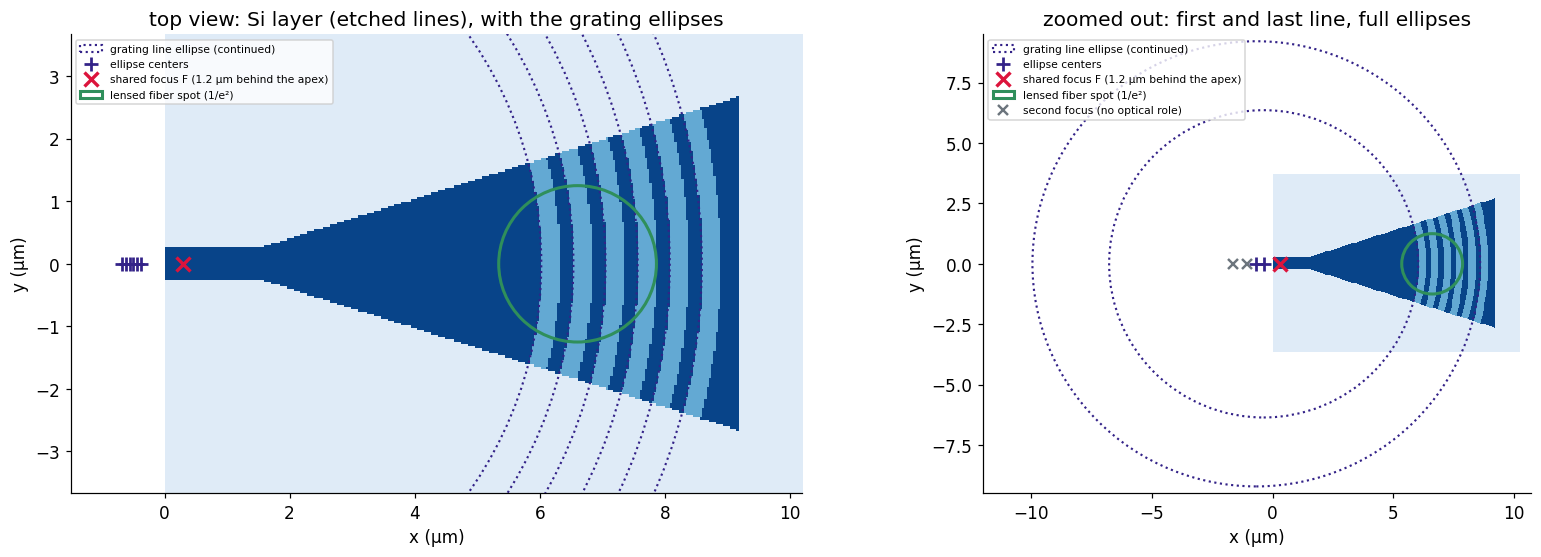

eccentricity e = -0.1062, b/a = 0.9943
line  a (um)  b (um)  center - F (um)
   1   6.400   6.364           -0.680
   2   6.974   6.935           -0.741
   3   7.549   7.506           -0.802
   4   8.123   8.077           -0.863
   5   8.698   8.648           -0.924
   6   9.272   9.220           -0.985


In [3]:
# Top view of the Si layer as simulated, with the grating ellipses, their centers and their foci.
D = DESIGN
x_apex = int(masks["x_apex"]) * dx                  # apex position in simulation x, um
xF = x_apex - D["focus_offset_um"]                   # shared ellipse focus F, simulation x
sin_t = math.sin(math.radians(D["theta_deg"]))
e = N_OX * sin_t / D["n_bloch"]                      # eccentricity (sign: which side the center falls)
q0 = (D["n_bloch"] - N_OX * sin_t) * (D["r0_um"] + D["focus_offset_um"]) / WL0   # first line, on the axis at r0


def ellipse_geometry(q):
    # rho(phi) = p / (1 - e cos(phi)) around F, p = q*lambda/n_B: center offset, semi-axes, second focus.
    p = q * WL0 / D["n_bloch"]
    a, b = p / (1 - e**2), p / math.sqrt(1 - e**2)
    xc = xF + p * e / (1 - e**2)                      # e < 0: the center sits behind F
    return {"xc": xc, "a": a, "b": b, "x_focus2": 2 * xc - xF}


si, gr = masks["si_mask_2d"], masks["groove_mask_2d"]
top = np.where(si & ~gr, 2, np.where(si, 1, 0))       # 2 = full Si, 1 = groove (partial etch), 0 = oxide
X, Y = top.shape[0] * dx, top.shape[1] * dx
lines = [ellipse_geometry(q0 + k + D["duty"]) for k in range(D["n_periods"])]   # inner edge of each etched band
fx = x_apex + FINAL["fiber"]["x0_from_grating_start_um"] + D["r0_um"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, (xlim, ylim, shown) in zip(axes, [((-1.5, X), (-Y / 2, Y / 2), lines),
                                          ((-12, X + 0.5), (-9.5, 9.5), [lines[0], lines[-1]])]):
    ax.imshow(top.T, origin="lower", cmap=style.CMAP_PERMITTIVITY_BASELINE, vmin=-0.3, vmax=2.2, aspect="equal",
              interpolation="nearest", extent=[0, X, -Y / 2, Y / 2])
    for i, g in enumerate(shown):
        ax.add_patch(Ellipse((g["xc"], 0), 2 * g["a"], 2 * g["b"], fill=False, ec=style.COLOR_INDIGO, ls=":", lw=1.4,
                             label="grating line ellipse (continued)" if i == 0 else None))
        ax.plot(g["xc"], 0, "+", color=style.COLOR_INDIGO, ms=9, mew=1.8, label="ellipse centers" if i == 0 else None)
    ax.plot(xF, 0, "x", color=style.COLOR_ANNOTATION, ms=9, mew=2.2,
            label=f"shared focus F ({D['focus_offset_um']} µm behind the apex)")
    ax.add_patch(Ellipse((fx, 0), 2 * 1.25 / math.cos(math.radians(FINAL["fiber"]["theta_deg"])), 2.5,
                         fill=False, ec=style.COLOR_SEAGREEN, lw=2, label="lensed fiber spot (1/e²)"))
    ax.set(xlim=xlim, ylim=ylim, xlabel="x (µm)", ylabel="y (µm)")
    ax.grid(False)
for g in (lines[0], lines[-1]):
    axes[1].plot(g["x_focus2"], 0, "x", color=style.COLOR_REFERENCE, ms=7, mew=1.6)
axes[1].plot([], [], "x", color=style.COLOR_REFERENCE, ms=7, mew=1.6, label="second focus (no optical role)")
axes[0].set_title("top view: Si layer (etched lines), with the grating ellipses")
axes[1].set_title("zoomed out: first and last line, full ellipses")
axes[0].legend(fontsize=7, loc="upper left")
axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

print(f"eccentricity e = {e:+.4f}, b/a = {math.sqrt(1 - e**2):.4f}")
print(f"{'line':>4} {'a (um)':>7} {'b (um)':>7} {'center - F (um)':>16}")
for k, g in enumerate(lines):
    print(f"{k + 1:>4} {g['a']:>7.3f} {g['b']:>7.3f} {g['xc'] - xF:>16.3f}")

## 4. Final device: power, fiber coupling and fields

**Coupling efficiency.** η = |c|² / (P_fib · P_launched), with
c = ¼ ∫ (E_sim × H*_fib + E*_fib × H_sim) · ẑ dA on a plane 0.5 µm above the Si.
- E_sim, H_sim: the simulated emitted field on that plane.
- E_fib, H_fib: a tilted Gaussian beam with the lensed fiber's 2.5 µm spot. Its power
  P_fib is analytic over the infinite plane.
- P_launched: the total power leaving a closed box of monitors around the device.

By reciprocity this is the fiber-to-chip coupling as well. η can never exceed the
fraction of power radiated upward, which acts as its ceiling.

**Fiber placement.** The fiber's position and tilt were optimized for maximum η at
1.35 µm and then held fixed for the whole spectrum, as a mounted fiber would be.

power at 1.35 um: up 0.832, down 0.013, reflection 0.100, transmission 0.052
emission decay length L_c = 1.37 um; mode match M_x = 0.942, M_y = 0.993
fiber: spot 2.5 um at +0.80 um from the grating start, tilt -7.5 deg in oxide (-10.8 deg in air)
expected (up x M_x x M_y x (1-R_F)) = 0.753 (-1.23 dB)
computed 3D overlap: eta = 0.710 (-1.49 dB); incl. Fresnel 0.687 (-1.63 dB)
peak -1.15 dB at 1.382 um; 1-dB band ~1.334-1.414 um


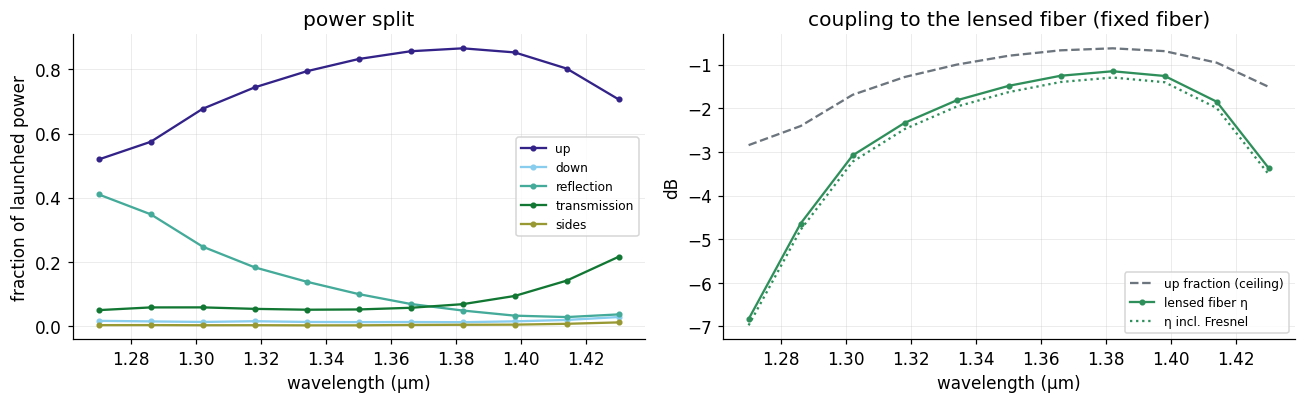

In [4]:
# Power split, fiber placement, expected vs computed efficiency, and the coupling spectrum.
F = FINAL["fiber"]
frac = {k: np.array(v) for k, v in FINAL["fractions"].items()}
spec = np.array(FINAL["eta_spectrum"])
print(f"power at 1.35 um: up {frac['up'][I0]:.3f}, down {frac['down'][I0]:.3f}, reflection {frac['reflection'][I0]:.3f}, "
      f"transmission {frac['transmission'][I0]:.3f}")
print(f"emission decay length L_c = {FINAL['L_c_um']:.2f} um; mode match M_x = {FINAL['M_x']:.3f}, M_y = {FINAL['M_y']:.3f}")
print(f"fiber: spot {F['spot_um']} um at {F['x0_from_grating_start_um']:+.2f} um from the grating start, "
      f"tilt {F['theta_deg']:+.1f} deg in oxide ({F['theta_air_deg']:+.1f} deg in air)")
print(f"expected (up x M_x x M_y x (1-R_F)) = {FINAL['eta_expected_incl_fresnel']:.3f} "
      f"({db(FINAL['eta_expected_incl_fresnel']):.2f} dB)")
print(f"computed 3D overlap: eta = {FINAL['eta_1350']:.3f} ({db(FINAL['eta_1350']):.2f} dB); incl. Fresnel "
      f"{FINAL['eta_1350_incl_fresnel']:.3f} ({db(FINAL['eta_1350_incl_fresnel']):.2f} dB)")
ok = db(spec) >= db(spec).max() - 1
print(f"peak {db(spec).max():.2f} dB at {WLS[np.argmax(spec)]:.3f} um; 1-dB band ~{WLS[ok].min():.3f}-{WLS[ok].max():.3f} um")
# Physical bound: the fiber can collect at most what is radiated upward.
assert np.all(spec <= frac["up"] + 1e-6), "coupling exceeds the upward power fraction"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (k, v), c in zip(frac.items(), style.COLOR_CYCLE):
    axes[0].plot(WLS, v, "o-", ms=3, color=c, label=k)
axes[0].set(xlabel="wavelength (µm)", ylabel="fraction of launched power", title="power split")
axes[0].legend(fontsize=8)
axes[1].plot(WLS, db(frac["up"]), "--", color=style.COLOR_REFERENCE, label="up fraction (ceiling)")
axes[1].plot(WLS, db(spec), "o-", ms=3, color=style.COLOR_SEAGREEN, label="lensed fiber η")
axes[1].plot(WLS, db(spec * (1 - R_F)), ":", color=style.COLOR_SEAGREEN, label="η incl. Fresnel")
axes[1].set(xlabel="wavelength (µm)", ylabel="dB", title="coupling to the lensed fiber (fixed fiber)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Reading the numbers.** The factorized estimate up × M_x × M_y × (1 − R_F) and the full
3D overlap differ by a few tenths of a dB, because the emitted beam is not perfectly
separable in x and y and carries a small residual phase. The remaining loss budget at
1.35 µm is back-reflection into the wire (~10 %), transmission past the grating (~5 %)
and mode mismatch (overlap ≈ 0.85). Apodizing the lines and suppressing the reflection
at the first groove are the next levers.

The three figures below were rendered from the 3D simulation's field data:
1. **Ports and fiber placement:** the side view through the axis (stack, mirror, flux
   box, fiber reference plane and fiber axis) and the top view of the Si layer as
   rasterized on the simulation grid.
2. **Fields:** Re(Ey) inside the Si layer (the cylindrical wave spreading through the
   fan and reaching the grating) and on the x-z plane through the axis.
3. **Fiber reference plane:** the emitted field, the fiber mode, and the overlap
   integrand that shows where the coupling comes from.

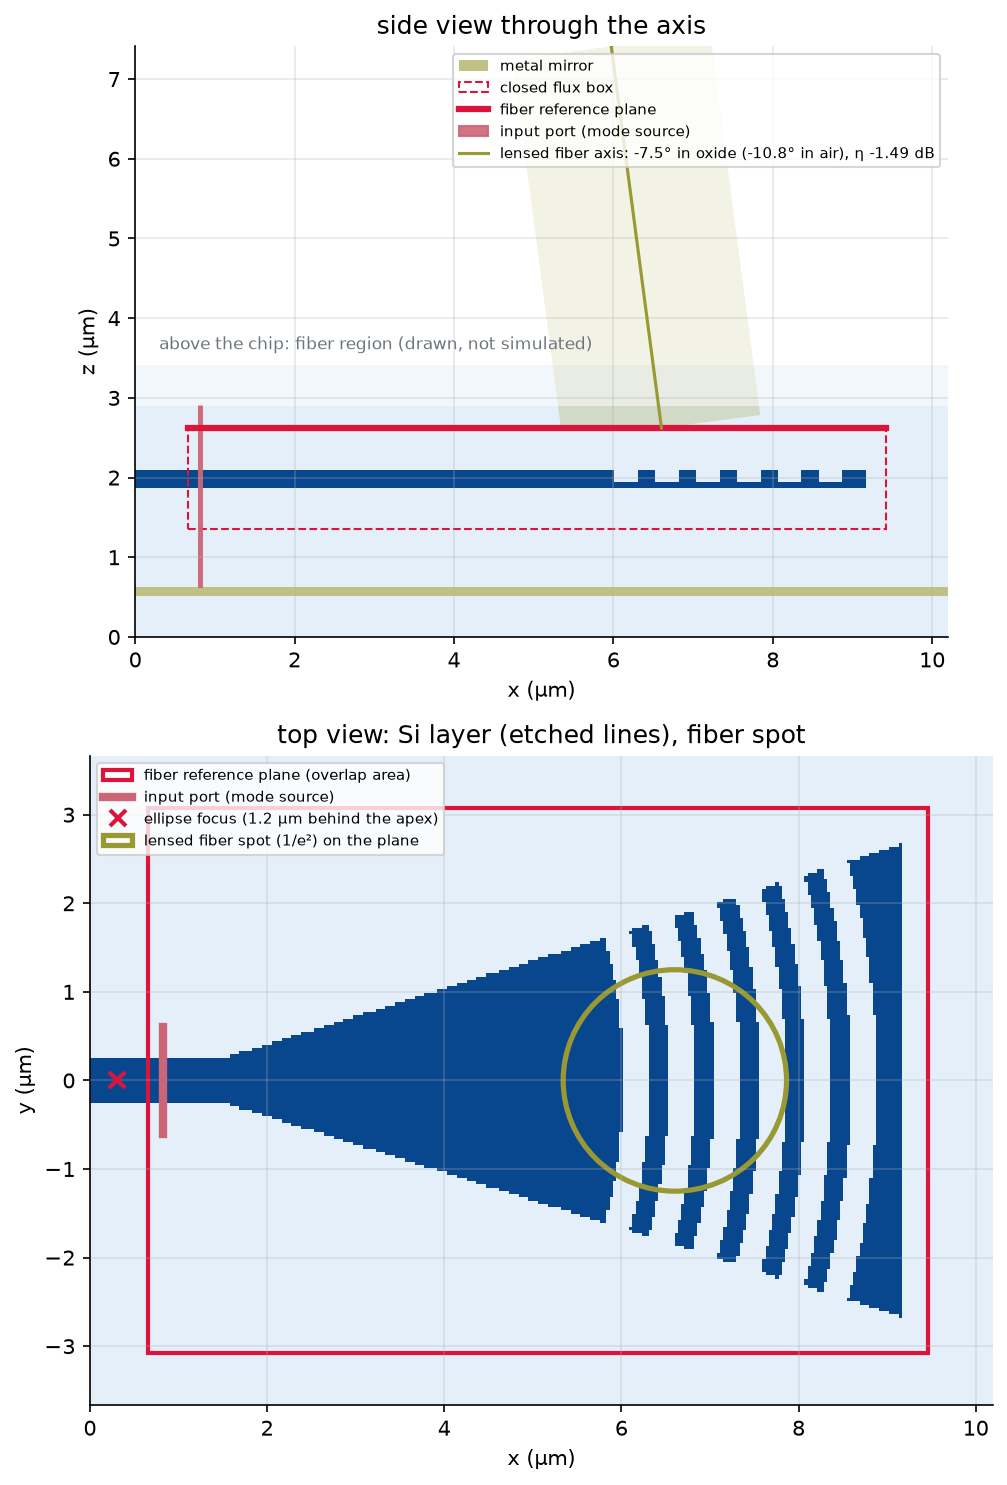

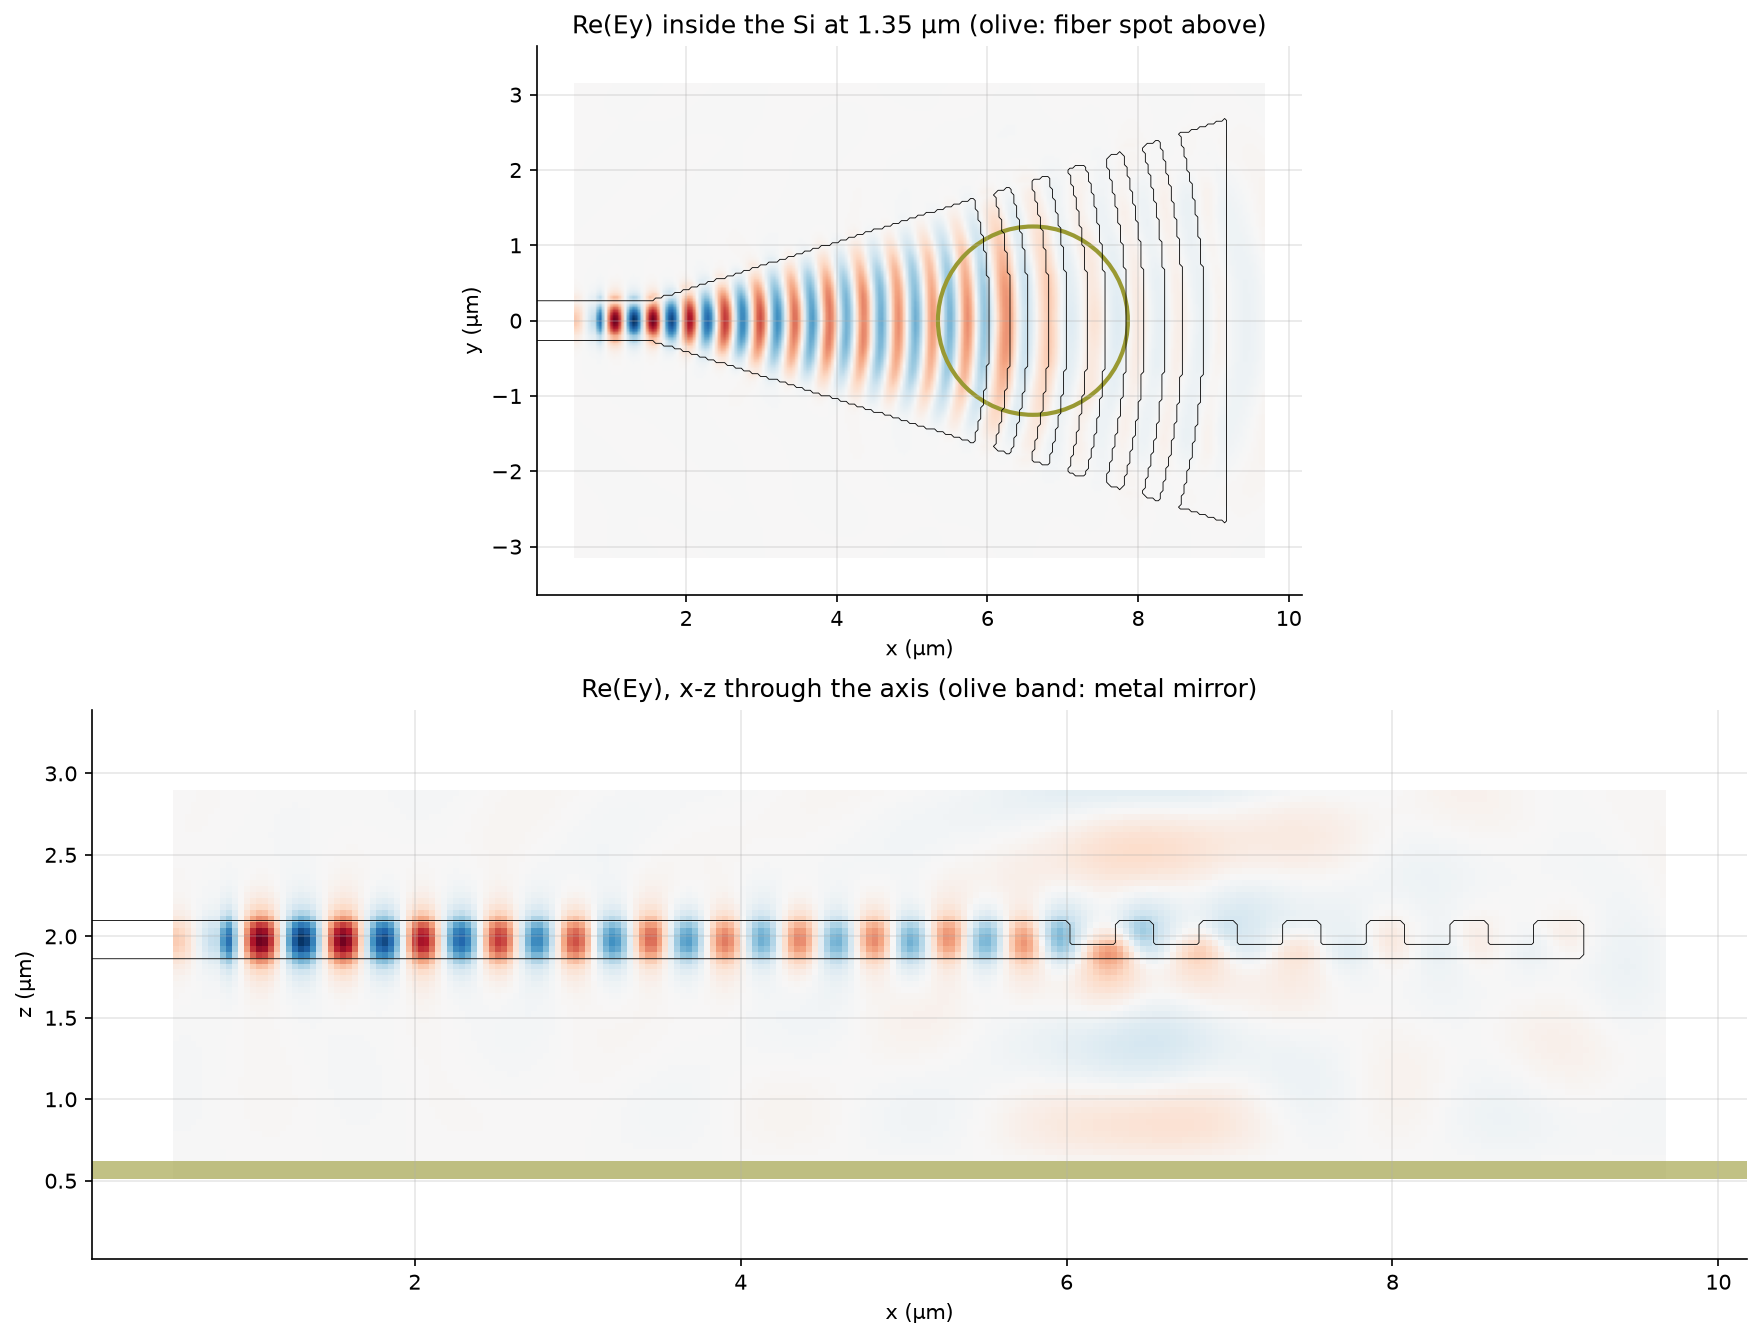

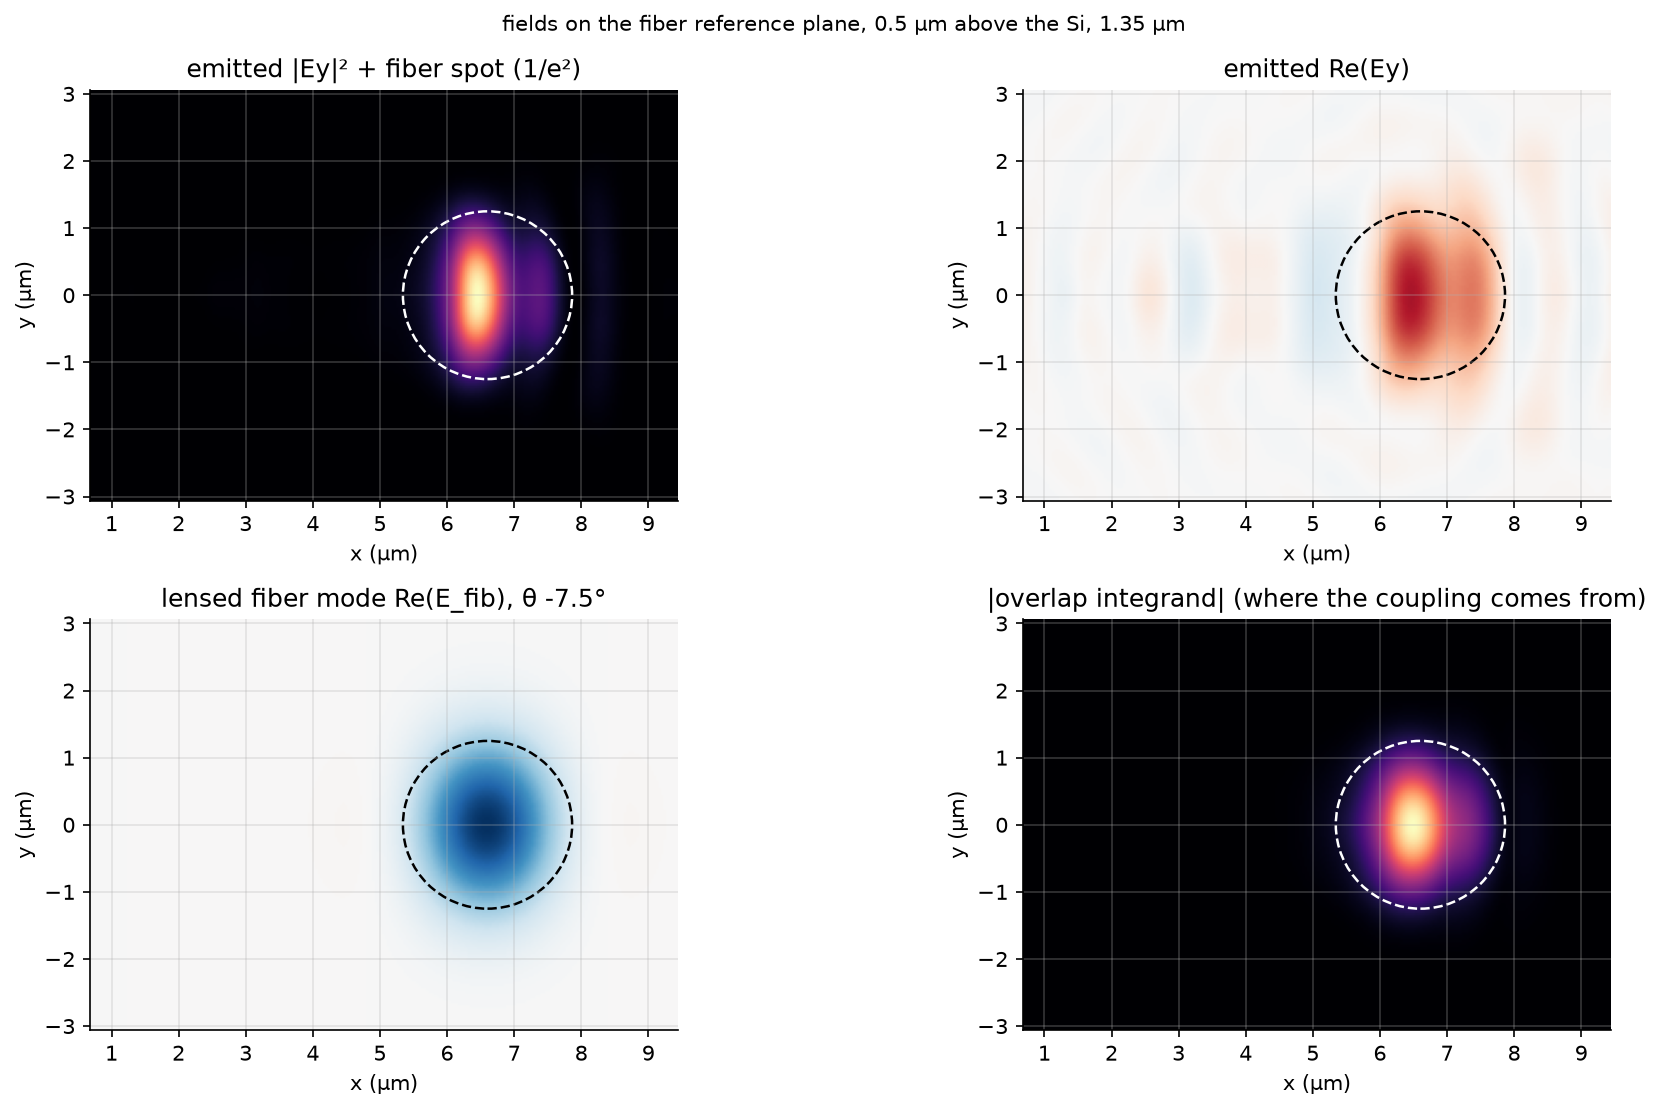

In [5]:
# The 3D figures saved with the simulation: ports and fiber placement, fields, fiber-plane overlap.
for name in ("ports_and_fiber.png", "fields_si_and_side.png", "fields_fiber_plane.png"):
    display(Image(filename=str(RESULTS / name), width=950))

> **STOP -- check the device before exporting it.** The Si-layer field should show a
> smooth cylindrical wave filling the fan with no sidewall leakage, and the overlap
> integrand should sit inside the fiber spot.

## 5. GDS export and the check against the simulated grid

The layout is the x-y footprint. A GDS file cannot encode the vertical stack, so the
BOX, top oxide and mirror are recorded in a text label and in the design point:
- `WG` (1/0): the full-thickness Si, i.e. the input wire plus the fan wedge (fully
  etched outside it).
- `SHALLOW_ETCH`: the partial-etch grating lines (147 nm into 220 nm). They are smooth
  elliptical bands from the focusing condition of Section 3, clipped to the fan with a
  gdsfactory boolean.
- `TEXT`: a fabrication label with the parameters a mask engineer needs at a glance.

**GDS vs the simulated geometry (CLAUDE.md §4).** The 3D simulation used the same design
rasterized onto 36.7 nm cells, each cell Si or groove according to its *center*. The
cells below rasterize the GDS polygons the same way and diff them against the masks the
simulation actually used. Any disagreement can only come from cells whose centers sit
within the polygon-arc discretization of an edge.

In [6]:
# Build the gdsfactory component from the design parameters (coordinates in um, apex at x = 0).
import gdsfactory as gf

# gdsfactory's generic PDK (active by default) provides the WG / SHALLOW_ETCH / TEXT layer names.
D = DESIGN
tan_a = math.tan(math.radians(D["half_angle_deg"]))
sin_t = math.sin(math.radians(D["theta_deg"]))
lam_ax = float(masks["axial_period_um"])
r_end = float(masks["r_end_um"])
fan_len = r_end + D["tail_um"]
half_end = D["w_in_um"] / 2 + fan_len * tan_a       # half-width of the fan at its far end
lead = D["lead_in_um"]

# Si: input wire + fan wedge, one polygon
si_poly = [(-lead, -D["w_in_um"] / 2), (0, -D["w_in_um"] / 2), (fan_len, -half_end), (fan_len, half_end),
           (0, D["w_in_um"] / 2), (-lead, D["w_in_um"] / 2)]

# Grating lines: in polar coordinates centered on the ellipse focus F (focus_offset_um behind the
# apex), line q is rho(phi) = q*lambda / (n_B - n_ox*sin(theta)*cos(phi)) (Section 3). q0 puts the
# first line at r0 from the apex on the axis.
q0 = (D["n_bloch"] - N_OX * sin_t) * (D["r0_um"] + D["focus_offset_um"]) / WL0
phis = np.radians(np.linspace(-(D["half_angle_deg"] + 15), D["half_angle_deg"] + 15, 721))


def arc(q):
    rho = q * WL0 / (D["n_bloch"] - N_OX * sin_t * np.cos(phis))
    return np.stack([rho * np.cos(phis) - D["focus_offset_um"], rho * np.sin(phis)], axis=1)


fan_c = gf.Component()
fan_c.add_polygon(si_poly, layer="WG")
bands_c = gf.Component()
for k in range(D["n_periods"]):
    a, b = arc(q0 + k + D["duty"]), arc(q0 + k + 1)        # etched band: from the end of the tooth to the period end
    bands_c.add_polygon(np.vstack([a, b[::-1]]), layer="SHALLOW_ETCH")
etch_c = gf.boolean(bands_c, fan_c, operation="and", layer1="SHALLOW_ETCH", layer2="WG", layer="SHALLOW_ETCH")

GC = gf.Component("fan_grating_coupler_3d")
GC.add_polygon(si_poly, layer="WG")
GC.add_ref(etch_c)
GC.add_port("o1", center=(-lead, 0), width=D["w_in_um"], orientation=180, layer="WG")
label = (f"FAN GC: half_angle={D['half_angle_deg']}deg r0={D['r0_um']}um n_lines={D['n_periods']} "
         f"axial_period={lam_ax * 1e3:.1f}nm duty={D['duty']:.3f} etch={round(D['etch_um'] / dx) * dx * 1e3:.0f}nm/220nm "
         f"focus={D['focus_offset_um']}um_behind_apex | stack: BOX {D['box_um']:.3f}um on {D['mirror']} mirror, "
         f"top oxide {D['clad_um']}um | fiber: lensed 2.5um spot, {FINAL['fiber']['theta_air_deg']:+.1f}deg in air")
GC.add_label(text=label, position=(fan_len / 2, half_end + 1.5), layer="TEXT")
print(label)

FAN GC: half_angle=17.5deg r0=4.3um n_lines=6 axial_period=513.4nm duty=0.429 etch=147nm/220nm focus=1.2um_behind_apex | stack: BOX 1.247um on metal mirror, top oxide 0.8um | fiber: lensed 2.5um spot, -10.8deg in air


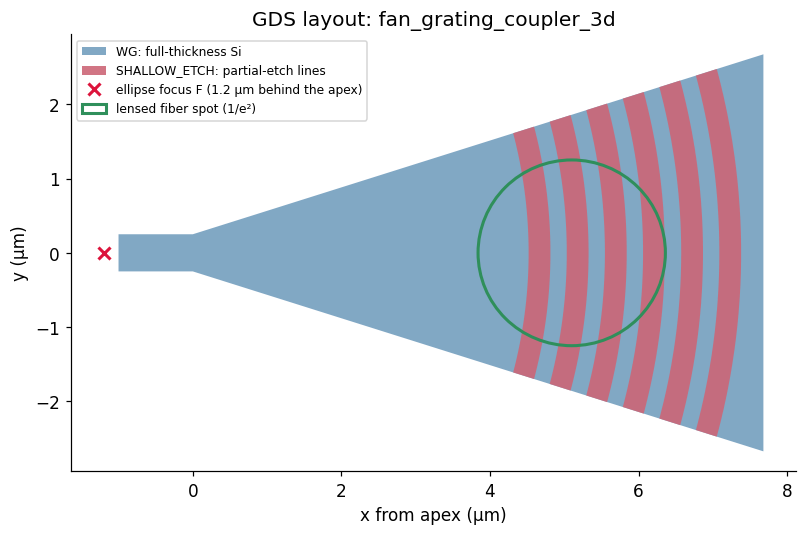

In [7]:
# Plot the layout: Si, partial-etch lines, the ellipse focus and the fiber spot.
polys = GC.get_polygons_points(by="name")
fig, ax = plt.subplots(figsize=(11, 5))
for layer_name, color, lab in (("WG", style.COLOR_STEEL, "WG: full-thickness Si"),
                               ("SHALLOW_ETCH", style.COLOR_ROSE, "SHALLOW_ETCH: partial-etch lines")):
    for i, p in enumerate(polys.get(layer_name, [])):
        ax.fill(p[:, 0], p[:, 1], color=color, alpha=0.6 if layer_name == "WG" else 0.9, lw=0,
                label=lab if i == 0 else None)
ax.plot(-D["focus_offset_um"], 0, "x", color=style.COLOR_ANNOTATION, ms=8, mew=2, label=f"ellipse focus F ({D['focus_offset_um']} µm behind the apex)")
fx = D["r0_um"] + FINAL["fiber"]["x0_from_grating_start_um"]
ax.add_patch(Ellipse((fx, 0), 2 * 1.25 / math.cos(math.radians(FINAL["fiber"]["theta_deg"])), 2.5,
                     fill=False, ec=style.COLOR_SEAGREEN, lw=2, label="lensed fiber spot (1/e²)"))
ax.set(aspect="equal", xlabel="x from apex (µm)", ylabel="y (µm)", title="GDS layout: fan_grating_coupler_3d")
ax.grid(False)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
# Rasterize the GDS at the simulation's cell centers (relative to the apex, y centered) and
# diff it against the masks the 3D simulation actually used.
nx, ny, x_apex = int(masks["nx"]), int(masks["ny"]), int(masks["x_apex"])
xc = (np.arange(nx) + 0.5 - x_apex) * dx
yc = (np.arange(ny) + 0.5 - ny / 2) * dx
XY = np.stack(np.meshgrid(xc, yc, indexing="ij"), axis=-1).reshape(-1, 2)


def raster(layer_name):
    m = np.zeros(nx * ny, dtype=bool)
    for p in polys.get(layer_name, []):
        m |= MplPath(p).contains_points(XY)
    return m.reshape(nx, ny)


sim_si, sim_gr = masks["si_mask_2d"], masks["groove_mask_2d"]
gds_si, gds_gr = raster("WG"), raster("SHALLOW_ETCH")
# the simulated wire also runs on into the -x PML; compare only the drawn part (x >= -lead)
inside = np.broadcast_to(xc[:, None] > -lead + 1e-9, (nx, ny))
gds_diff = {}
for key, name, a, b in (("si", "Si (WG)", gds_si, sim_si), ("lines", "grating lines", gds_gr, sim_gr)):
    diff = (a != b) & inside
    gds_diff[key] = int(diff.sum())
    print(f"{name:>14}: {diff.sum():5d} of {b[inside].sum():6d} cells differ ({diff.sum() / max(b[inside].sum(), 1):.2%} of the feature)")
# Edge-discretization only: well under 1% of each feature's cells.
assert gds_diff["si"] < 0.01 * sim_si[inside].sum() and gds_diff["lines"] < 0.01 * sim_gr[inside].sum(), \
    "GDS and simulated masks disagree by more than edge discretization"

       Si (WG):     2 of  17000 cells differ (0.01% of the feature)
 grating lines:    14 of   5400 cells differ (0.26% of the feature)


> **STOP -- check the layout and the diff before writing the GDS.** The etched lines
> should be smooth arcs clipped to the fan, and only a handful of edge cells should
> differ from the simulated masks.

In [9]:
# Write the GDS file.
gds_path = GC.write_gds(GDS_PATH)
print("wrote", gds_path)

wrote /home/yuma/meep-course/photonics-simulation-toolkit/3d/data/gds/fan_grating_coupler_3d.gds


## 6. Design point

The record follows the toolkit's design-point schema
(`component / parameters / measured / provenance / validation / rationale`), plus the
fiber placement and a list of limitations. It is saved to
`3d/data/design_points/grating_coupler_fan_3d.yaml`, separate from the 2D track's
`data/design_points/`, because it belongs to a different model (real 3D, bulk indices).

> **STOP -- the next cell writes the design point.**

In [10]:
# Design point for the final device: parameters, measured model, provenance, validation, limitations.
record = {
    "component": "grating_coupler_fan_3d",
    "parameters": {
        "wg_width_um": D["w_in_um"], "si_thickness_um": D["si_um"],
        "etch_depth_um": round(D["etch_um"] / dx) * dx, "fan_half_angle_deg": D["half_angle_deg"],
        "first_line_radius_um": D["r0_um"], "n_lines": D["n_periods"], "axial_period_um": lam_ax, "duty": D["duty"],
        "line_shape": "confocal ellipses n_B*r - n_ox*x*sin(theta) = q*lambda",
        "n_bloch": D["n_bloch"], "emission_angle_deg": D["theta_deg"], "focus_offset_um": D["focus_offset_um"],
        "box_um": D["box_um"], "top_oxide_um": D["clad_um"], "bottom_reflector": D["mirror"], "mirror_sigma_S_per_m": 4.0e7,
        "core_index": 3.45, "clad_index": N_OX, "design_wavelength_um": WL0,
    },
    "fiber": {"type": "lensed", "spot_diameter_1e2_um": 2.5, "na": 0.34,
              "x_from_grating_start_um": FINAL["fiber"]["x0_from_grating_start_um"],
              "tilt_deg_oxide": FINAL["fiber"]["theta_deg"], "tilt_deg_air": FINAL["fiber"]["theta_air_deg"]},
    "measured": {
        "wavelengths_um": WLS.tolist(),
        "eta_lensed": spec.tolist(), "eta_lensed_incl_fresnel": (spec * (1 - R_F)).tolist(),
        "fractions": {k: v.tolist() for k, v in frac.items()},
        "eta_1350": FINAL["eta_1350"], "eta_1350_db": float(db(FINAL["eta_1350"])),
        "eta_1350_incl_fresnel_db": float(db(FINAL["eta_1350_incl_fresnel"])),
        "emission_decay_length_um": FINAL["L_c_um"], "mode_match_x": FINAL["M_x"], "mode_match_y": FINAL["M_y"],
    },
    "provenance": {"method": "3D FDTD (fdtdx 0.6.0, JAX CPU), reciprocity overlap with a tilted Gaussian fiber mode",
                   "grid_um": dx, "n_voxels": FINAL["n_voxels"], "run_minutes": FINAL["timing"]["t_run_s"] / 60,
                   "date": "2026-10-11",
                   "results": "3d/data/results/grating_coupler_fan_3d/"},
    "validation": {"eta_le_up_fraction": bool(np.all(spec <= frac["up"] + 1e-6)),
                   "gds_vs_simulated_mask_cells_differing": gds_diff,
                   "power_normalization_grid_error": "forward/box flux ratio ~0.86-0.90 at 36.7 nm, converging as dx^2"},
    "limitations": [
        "only |c|^2 saved, not the complex coupling coefficient c(lambda); a SAX model would need its phase",
        "absolute fractions carry ~10% grid uncertainty at 36.7 nm cells",
        "metal mirror is a sigma=4e7 S/m stand-in, not a dispersive Au/Al model",
        "fiber modeled as a Gaussian waist on a plane in the oxide; Fresnel loss applied as a factor",
        "minimized aperture (6 lines, ~5 um) sized for a 2.5 um lensed spot, not SMF-28",
    ],
    "rationale": ("Fan half-angle 17.5 deg and r0 = 4.3 um make the beam width at the emission point match the "
                  "2.5 um lensed spot; ellipse focus 1.2 um behind the apex = phase center of the fan wave; "
                  "BOX 1.25 um on a metal mirror = in-phase bottom reflection. Fiber position and tilt optimized "
                  "at 1.35 um, then held fixed for the spectrum."),
}
save_design_point(DESIGN_POINT_PATH, record)
print("saved", DESIGN_POINT_PATH)
print("keys:", list(record))

saved /home/yuma/meep-course/photonics-simulation-toolkit/3d/data/design_points/grating_coupler_fan_3d.yaml
keys: ['component', 'parameters', 'fiber', 'measured', 'provenance', 'validation', 'limitations', 'rationale']


## 7. Limitations

These are also recorded in the design point.
- **Grid.** At 36.7 nm cells, absolute power fractions carry about ±10 %. Comparisons
  between quantities on the same grid are much tighter.
- **Mirror.** The metal is a conductivity stand-in. A real Au/Al mirror needs a
  dispersive material model.
- **Fiber.** A Gaussian beam on a plane in the oxide. Refraction at the chip surface is
  handled through the tilt angle and the Fresnel factor; working-distance defocus is
  not modeled.
- **Phase.** Only |c|² was saved, not the complex coupling coefficient. A SAX
  waveguide ↔ fiber model needs c(λ) with its phase (CLAUDE.md §7).
- **Aperture.** The design is minimized for a 2.5 µm lensed spot. Coupling to SMF-28
  (9.2 µm mode field diameter) needs a ~12 µm aperture and 20+ lines, a several-times
  larger 3D cell.